# Work with Inner Merged DFs
I have an idea that the outcomes might be different if we would use only the limited data. I want to test this approach as well.

In [159]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

1. Reading all .csv files into dataframes:

In [183]:
df_orders = pd.read_csv('../data_csv/orders.csv')
df_orders.columns = df_orders.columns.str.lower()
df_orders.columns = df_orders.columns.str.replace(' ','_')
df_orders['total_items'] = df_orders.groupby("order_id")["quantity"].transform("sum")
df_orders = df_orders.drop(columns=['customer_id', 'customer_name','country/region', 
'city','state', 'postal_code','category', 'product_id', 'sales', 'discount','profit', 'sub-category', 'quantity'])
df_orders.rename(columns={"index": "row_id"}, inplace=True)
df_orders.to_csv('../data_csv/orders_min.csv')

df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   row_id          9994 non-null   int64
 1   order_id        9994 non-null   str  
 2   order_date      9994 non-null   str  
 3   ship_mode       9994 non-null   str  
 4   origin_channel  9994 non-null   str  
 5   region          9994 non-null   str  
 6   total_items     9994 non-null   int64
dtypes: int64(2), str(5)
memory usage: 546.7 KB


In [184]:
df_interns = pd.read_csv('../data_csv/intern_unique.csv')
df_interns = df_interns.drop(columns=['Unnamed: 0','ready_ship_year','ready_ship_month', 
'ready_ship_weekday', 'pickup_year', 'pickup_month', 'pickup_weekday'])
df_interns.to_csv('../data_csv/interns_min.csv')
df_interns.info()

<class 'pandas.DataFrame'>
RangeIndex: 204 entries, 0 to 203
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   order_id            204 non-null    str  
 1   ready_to_ship_date  204 non-null    str  
 2   pickup_date         204 non-null    str  
dtypes: str(3)
memory usage: 4.9 KB


In [247]:
df_process = pd.read_csv('../data_csv/process_clean.csv')
df_process = df_process.drop(columns=['order_id','order_date','order_year','order_month', 'order_weekday',
'truck_year', 'truck_month', 'truck_weekday'])
df_process.rename(columns={"ship_mode": "truck_ship_mode"}, inplace=True)
df_process.to_csv('../data_csv/process_min.csv')
df_process.info()

<class 'pandas.DataFrame'>
RangeIndex: 5899 entries, 0 to 5898
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   row_id              5899 non-null   int64
 1   on_truck_scan_date  5899 non-null   str  
 2   truck_ship_mode     5899 non-null   str  
dtypes: int64(1), str(2)
memory usage: 138.4 KB


In [186]:
df_scan = pd.read_csv('../data_csv/campaign_clean.csv')
df_scan = df_scan.drop(columns=['customer_name', 'arrival_year', 'arrival_month','arrival_day', 'arrival_weekday'])
df_scan.to_csv('../data_csv/scan_min.csv')
df_scan.info()

<class 'pandas.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   order_id           333 non-null    str  
 1   arrival_scan_date  333 non-null    str  
dtypes: str(2)
memory usage: 5.3 KB


In [187]:
print(df_orders.shape)
print(df_process.shape)

(9994, 7)
(5899, 3)


In [173]:
df_short = df_orders.merge(df_process, how='outer', on='row_id')
df_short.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   row_id              9994 non-null   int64
 1   order_id            9994 non-null   str  
 2   order_date          9994 non-null   str  
 3   ship_mode           9994 non-null   str  
 4   origin_channel      9994 non-null   str  
 5   region              9994 non-null   str  
 6   total_items         9994 non-null   int64
 7   on_truck_scan_date  5899 non-null   str  
 8   truck_ship_mode     5899 non-null   str  
dtypes: int64(2), str(7)
memory usage: 702.8 KB


In [188]:
print(df_short[["order_id"]].duplicated().value_counts())

False    5009
True     4985
Name: count, dtype: int64


In [189]:
df_unique = df_short.drop_duplicates(subset="order_id", keep="first")
df_unique = df_unique.drop(columns=['row_id'])

In [176]:
df_unique.info()

<class 'pandas.DataFrame'>
Index: 5009 entries, 0 to 9993
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   order_id            5009 non-null   str  
 1   order_date          5009 non-null   str  
 2   ship_mode           5009 non-null   str  
 3   origin_channel      5009 non-null   str  
 4   region              5009 non-null   str  
 5   total_items         5009 non-null   int64
 6   on_truck_scan_date  3002 non-null   str  
 7   truck_ship_mode     3002 non-null   str  
dtypes: int64(1), str(7)
memory usage: 352.2 KB


In [190]:
df_interns.head()

,order_id,ready_to_ship_date,pickup_date
0,CA-2019-116540,2019-09-02,2019-09-03
1,CA-2019-129847,2019-09-04,2019-09-04
2,CA-2019-129630,2019-09-04,2019-09-04
3,CA-2019-106278,2019-09-05,2019-09-06
4,CA-2019-158099,2019-09-05,2019-09-06


In [191]:
df_unique_add = df_unique.merge(df_interns,how = 'left', on='order_id')
df_unique_add.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   order_id            5009 non-null   str  
 1   order_date          5009 non-null   str  
 2   ship_mode           5009 non-null   str  
 3   origin_channel      5009 non-null   str  
 4   region              5009 non-null   str  
 5   total_items         5009 non-null   int64
 6   on_truck_scan_date  3002 non-null   str  
 7   truck_ship_mode     3002 non-null   str  
 8   ready_to_ship_date  204 non-null    str  
 9   pickup_date         204 non-null    str  
dtypes: int64(1), str(9)
memory usage: 391.5 KB


In [192]:
df_unique_all = df_unique_add.merge(df_scan, how='left', on='order_id')
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   order_id            5009 non-null   str  
 1   order_date          5009 non-null   str  
 2   ship_mode           5009 non-null   str  
 3   origin_channel      5009 non-null   str  
 4   region              5009 non-null   str  
 5   total_items         5009 non-null   int64
 6   on_truck_scan_date  3002 non-null   str  
 7   truck_ship_mode     3002 non-null   str  
 8   ready_to_ship_date  204 non-null    str  
 9   pickup_date         204 non-null    str  
 10  arrival_scan_date   333 non-null    str  
dtypes: int64(1), str(10)
memory usage: 430.6 KB


In [193]:
df_unique_all.to_csv('../data_csv/working_file.csv')

Dealimg with formats:

In [194]:
df_unique_all["order_date"] = pd.to_datetime(df_unique_all["order_date"])
df_unique_all["ready_to_ship_date"] = pd.to_datetime(df_unique_all["ready_to_ship_date"])
df_unique_all["pickup_date"] = pd.to_datetime(df_unique_all["pickup_date"])
df_unique_all["on_truck_scan_date"] = pd.to_datetime(df_unique_all["on_truck_scan_date"])
df_unique_all["arrival_scan_date"] = pd.to_datetime(df_unique_all["arrival_scan_date"])
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            5009 non-null   str           
 1   order_date          5009 non-null   datetime64[us]
 2   ship_mode           5009 non-null   str           
 3   origin_channel      5009 non-null   str           
 4   region              5009 non-null   str           
 5   total_items         5009 non-null   int64         
 6   on_truck_scan_date  3002 non-null   datetime64[us]
 7   truck_ship_mode     3002 non-null   str           
 8   ready_to_ship_date  204 non-null    datetime64[us]
 9   pickup_date         204 non-null    datetime64[us]
 10  arrival_scan_date   333 non-null    datetime64[us]
dtypes: datetime64[us](5), int64(1), str(5)
memory usage: 430.6 KB


New Variables / KPIs in Business Days

In [195]:
# processing_time
# calculated as:
# order date -------> ready to ship
mask = df_unique_all["order_date"].notna() & df_unique_all["ready_to_ship_date"].notna()

df_unique_all.loc[mask, "process_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "order_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "ready_to_ship_date"].values.astype("datetime64[D]")
)

df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            5009 non-null   str           
 1   order_date          5009 non-null   datetime64[us]
 2   ship_mode           5009 non-null   str           
 3   origin_channel      5009 non-null   str           
 4   region              5009 non-null   str           
 5   total_items         5009 non-null   int64         
 6   on_truck_scan_date  3002 non-null   datetime64[us]
 7   truck_ship_mode     3002 non-null   str           
 8   ready_to_ship_date  204 non-null    datetime64[us]
 9   pickup_date         204 non-null    datetime64[us]
 10  arrival_scan_date   333 non-null    datetime64[us]
 11  process_days_biz    204 non-null    float64       
dtypes: datetime64[us](5), float64(1), int64(1), str(5)
memory usage: 469.7 KB


In [196]:
# truck waiting days
# calculated as:
# ready to ship ------> pickup date
# according to interns
mask = df_unique_all["pickup_date"].notna() & df_unique_all["ready_to_ship_date"].notna()

df_unique_all.loc[mask, "truck_wait_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "ready_to_ship_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "pickup_date"].values.astype("datetime64[D]")
)
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_id             5009 non-null   str           
 1   order_date           5009 non-null   datetime64[us]
 2   ship_mode            5009 non-null   str           
 3   origin_channel       5009 non-null   str           
 4   region               5009 non-null   str           
 5   total_items          5009 non-null   int64         
 6   on_truck_scan_date   3002 non-null   datetime64[us]
 7   truck_ship_mode      3002 non-null   str           
 8   ready_to_ship_date   204 non-null    datetime64[us]
 9   pickup_date          204 non-null    datetime64[us]
 10  arrival_scan_date    333 non-null    datetime64[us]
 11  process_days_biz     204 non-null    float64       
 12  truck_wait_days_biz  204 non-null    float64       
dtypes: datetime64[us](5), float64(2), int64(1), 

In [197]:
# warehouse waiting days: pretty similar to truck waiting days; calculated from a different variable: 
# reday to ship ------> on truck scan
mask = df_unique_all["on_truck_scan_date"].notna() & df_unique_all["ready_to_ship_date"].notna()

df_unique_all.loc[mask, "war_wait_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "ready_to_ship_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "on_truck_scan_date"].values.astype("datetime64[D]")
)
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_id             5009 non-null   str           
 1   order_date           5009 non-null   datetime64[us]
 2   ship_mode            5009 non-null   str           
 3   origin_channel       5009 non-null   str           
 4   region               5009 non-null   str           
 5   total_items          5009 non-null   int64         
 6   on_truck_scan_date   3002 non-null   datetime64[us]
 7   truck_ship_mode      3002 non-null   str           
 8   ready_to_ship_date   204 non-null    datetime64[us]
 9   pickup_date          204 non-null    datetime64[us]
 10  arrival_scan_date    333 non-null    datetime64[us]
 11  process_days_biz     204 non-null    float64       
 12  truck_wait_days_biz  204 non-null    float64       
 13  war_wait_days_biz    204 non-null    float64

In [198]:
# transport days
# calculated as:
# on truck scan ------> arrival scan
mask = df_unique_all["arrival_scan_date"].notna() & df_unique_all["on_truck_scan_date"].notna()

df_unique_all.loc[mask, "transp_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "on_truck_scan_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "arrival_scan_date"].values.astype("datetime64[D]")
)

df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_id             5009 non-null   str           
 1   order_date           5009 non-null   datetime64[us]
 2   ship_mode            5009 non-null   str           
 3   origin_channel       5009 non-null   str           
 4   region               5009 non-null   str           
 5   total_items          5009 non-null   int64         
 6   on_truck_scan_date   3002 non-null   datetime64[us]
 7   truck_ship_mode      3002 non-null   str           
 8   ready_to_ship_date   204 non-null    datetime64[us]
 9   pickup_date          204 non-null    datetime64[us]
 10  arrival_scan_date    333 non-null    datetime64[us]
 11  process_days_biz     204 non-null    float64       
 12  truck_wait_days_biz  204 non-null    float64       
 13  war_wait_days_biz    204 non-null    float64

In [199]:
# total delivery time
# calculated:
# order date ------> arrival scan

mask = df_unique_all["order_date"].notna() & df_unique_all["arrival_scan_date"].notna()

df_unique_all.loc[mask, "total_delivery_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "order_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "arrival_scan_date"].values.astype("datetime64[D]")
)

df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   order_id                 5009 non-null   str           
 1   order_date               5009 non-null   datetime64[us]
 2   ship_mode                5009 non-null   str           
 3   origin_channel           5009 non-null   str           
 4   region                   5009 non-null   str           
 5   total_items              5009 non-null   int64         
 6   on_truck_scan_date       3002 non-null   datetime64[us]
 7   truck_ship_mode          3002 non-null   str           
 8   ready_to_ship_date       204 non-null    datetime64[us]
 9   pickup_date              204 non-null    datetime64[us]
 10  arrival_scan_date        333 non-null    datetime64[us]
 11  process_days_biz         204 non-null    float64       
 12  truck_wait_days_biz      204 non-null    floa

Add the days of the week for each action (to see distributions later and to get rid of the date columns)

In [200]:
# order:
df_unique_all["order_weekday"]=df_unique_all["order_date"].dt.dayofweek
# became integer because there are no missing values

# ready to ship (warehouse):
df_unique_all["ready_ship_weekday"]=df_unique_all["ready_to_ship_date"].dt.dayofweek
# became float because there are missing values

# pickup date (interns):
df_unique_all["pickup_weekday"]=df_unique_all["pickup_date"].dt.dayofweek

# on truck scan (logistics company):
df_unique_all["on_truck_weekday"]=df_unique_all["on_truck_scan_date"].dt.dayofweek

# arrival scan (user):
df_unique_all["arrival_weekday"]=df_unique_all["arrival_scan_date"].dt.dayofweek

df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   order_id                 5009 non-null   str           
 1   order_date               5009 non-null   datetime64[us]
 2   ship_mode                5009 non-null   str           
 3   origin_channel           5009 non-null   str           
 4   region                   5009 non-null   str           
 5   total_items              5009 non-null   int64         
 6   on_truck_scan_date       3002 non-null   datetime64[us]
 7   truck_ship_mode          3002 non-null   str           
 8   ready_to_ship_date       204 non-null    datetime64[us]
 9   pickup_date              204 non-null    datetime64[us]
 10  arrival_scan_date        333 non-null    datetime64[us]
 11  process_days_biz         204 non-null    float64       
 12  truck_wait_days_biz      204 non-null    floa

In [201]:
df_unique_all = df_unique_all.drop(columns=['order_date','on_truck_scan_date', 'ready_to_ship_date',
                                            'pickup_date', 'arrival_scan_date'])

In [202]:
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   order_id                 5009 non-null   str    
 1   ship_mode                5009 non-null   str    
 2   origin_channel           5009 non-null   str    
 3   region                   5009 non-null   str    
 4   total_items              5009 non-null   int64  
 5   truck_ship_mode          3002 non-null   str    
 6   process_days_biz         204 non-null    float64
 7   truck_wait_days_biz      204 non-null    float64
 8   war_wait_days_biz        204 non-null    float64
 9   transp_days_biz          333 non-null    float64
 10  total_delivery_days_biz  333 non-null    float64
 11  order_weekday            5009 non-null   int32  
 12  ready_ship_weekday       204 non-null    float64
 13  pickup_weekday           204 non-null    float64
 14  on_truck_weekday         3002 non-n

## Distribution of Orders by Weekdays

This representation is not perfect because we work only with those orders which were registered on the truck (3002 entries). Makes sense to use all the orders (5000+), so for this plot see a different JupNotebook.

--------------------------- Days when the orders are registered in the system:       ---------------------------
 order_weekday
0    0.145738
1    0.176482
2    0.168896
3    0.176682
4    0.157716
5    0.091435
6    0.083051
Name: proportion, dtype: float64 
---------------------------


/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_1219/2593747121.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


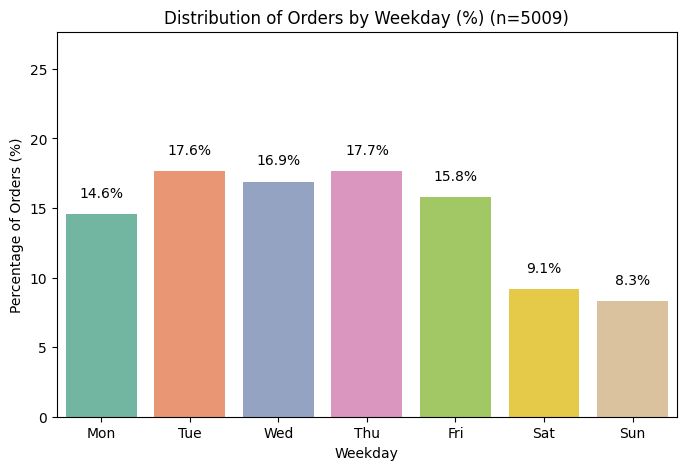

In [203]:
# sample size count:
n = df_unique_all["order_weekday"].dropna().shape[0]

# distribution + normalization:
weekday_counts = df_unique_all["order_weekday"].value_counts(normalize=True).sort_index()
print(f'--------------------------- Days when the orders are registered in the system: \
      ---------------------------\n {weekday_counts} \n---------------------------')
weekday_labels = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

# counting percentage:
weekday_percent = weekday_counts * 100

# plot: 
plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title(f"Distribution of Orders by Weekday (%) (n={n})")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()


In [71]:
df_unique_all.columns

Index(['order_id', 'ship_mode', 'origin_channel', 'region', 'total_items',
       'truck_ship_mode', 'process_days_biz', 'truck_wait_days_biz',
       'war_wait_days_biz', 'transp_days_biz', 'total_delivery_days_biz',
       'order_weekday', 'ready_ship_weekday', 'pickup_weekday',
       'on_truck_weekday', 'arrival_weekday'],
      dtype='str')

--------------------------- Days on which the shipment is marked ready in the warehouse:       ---------------------------
 ready_ship_weekday
0.0    0.455882
1.0    0.142157
2.0    0.112745
3.0    0.137255
4.0    0.151961
Name: proportion, dtype: float64 
---------------------------


/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_1219/3810739824.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


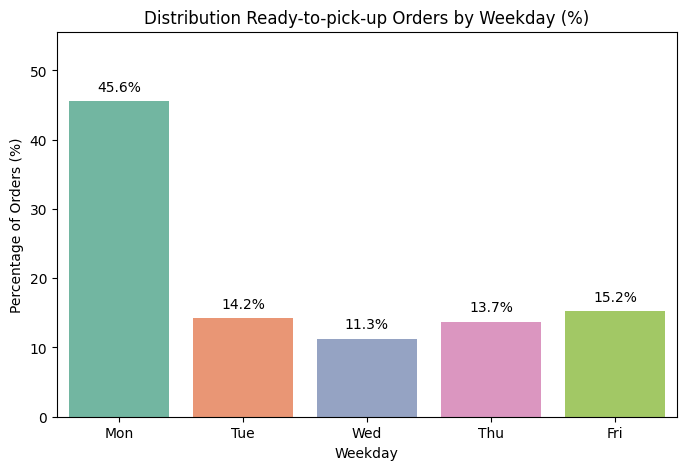

In [204]:
weekday_counts = df_unique_all["ready_ship_weekday"].value_counts(normalize=True).sort_index()
print(f'--------------------------- Days on which the shipment is marked ready in the warehouse: \
      ---------------------------\n {weekday_counts} \n---------------------------')
weekday_labels = ["Mon","Tue","Wed","Thu","Fri"] # they don't work on Sat and Sun + I checked

weekday_percent = weekday_counts * 100

plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title("Distribution Ready-to-pick-up Orders by Weekday (%)")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()


--------------------------- Pickup days registered in the database:       ---------------------------
 pickup_weekday
0.0    0.196078
1.0    0.004902
2.0    0.455882
3.0    0.083333
4.0    0.259804
Name: proportion, dtype: float64 
---------------------------


/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_1219/4201317761.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


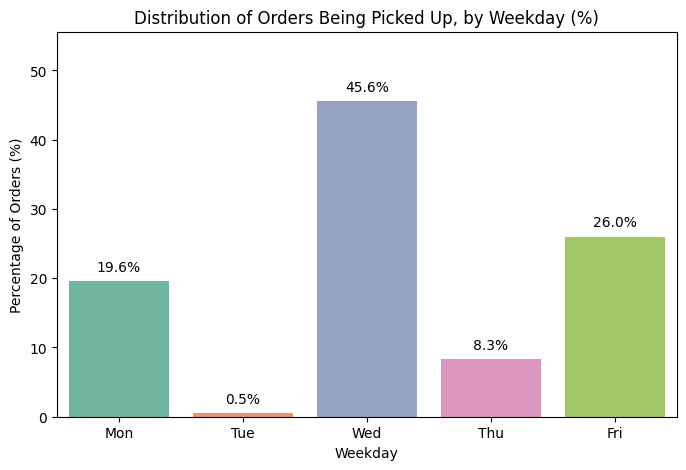

In [205]:
weekday_counts = df_unique_all["pickup_weekday"].value_counts(normalize=True).sort_index()
print(f'--------------------------- Pickup days registered in the database: \
      ---------------------------\n {weekday_counts} \n---------------------------')
weekday_labels = ["Mon","Tue","Wed","Thu","Fri"]

weekday_percent = weekday_counts * 100

plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title("Distribution of Orders Being Picked Up, by Weekday (%)")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()


--------------------------- Truck Scan Days registered in the database:       ---------------------------
 on_truck_weekday
0.0    0.182545
1.0    0.025650
2.0    0.551299
3.0    0.015323
4.0    0.225183
Name: proportion, dtype: float64 
---------------------------


/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_1219/1428352104.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


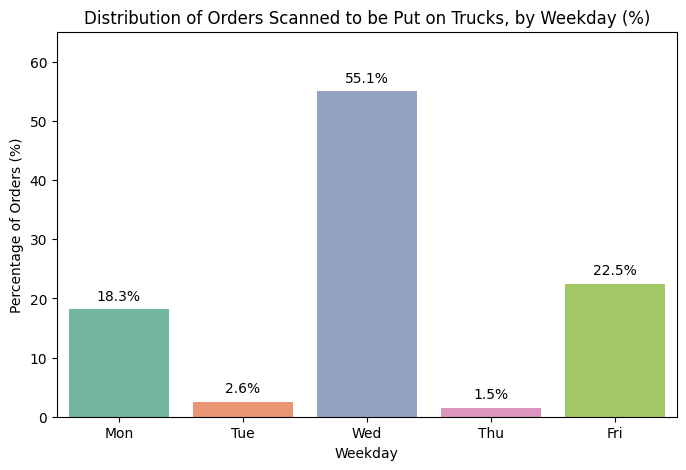

In [206]:
# Index(['order_id', 'ship_mode', 'origin_channel', 'region', 'total_items',
#        'truck_ship_mode', 'process_days_biz', 'truck_wait_days_biz',
#        'war_wait_days_biz', 'transp_days_biz', 'total_delivery_days_biz',
#        'order_weekday', 'ready_ship_weekday', 'pickup_weekday',
#        'on_truck_weekday', 'arrival_weekday'],

weekday_counts = df_unique_all["on_truck_weekday"].value_counts(normalize=True).sort_index()
print(f'--------------------------- Truck Scan Days registered in the database: \
      ---------------------------\n {weekday_counts} \n---------------------------')
weekday_labels = ["Mon","Tue","Wed","Thu","Fri"]

weekday_percent = weekday_counts * 100

plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title("Distribution of Orders Scanned to be Put on Trucks, by Weekday (%)")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()


--------------------------- Arrival Days registered in the database:       ---------------------------
 arrival_weekday
0.0    0.645646
1.0    0.120120
2.0    0.060060
3.0    0.057057
4.0    0.117117
Name: proportion, dtype: float64 
---------------------------


/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_1219/1618679383.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


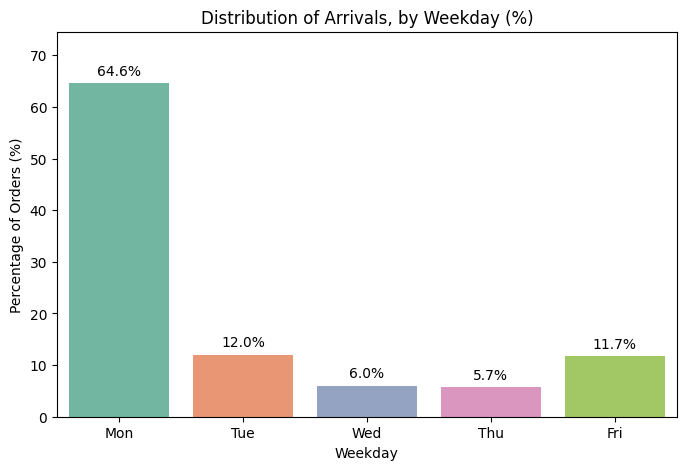

In [207]:
weekday_counts = df_unique_all["arrival_weekday"].value_counts(normalize=True).sort_index()
print(f'--------------------------- Arrival Days registered in the database: \
      ---------------------------\n {weekday_counts} \n---------------------------')
weekday_labels = ["Mon","Tue","Wed","Thu","Fri"]

weekday_percent = weekday_counts * 100

plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title("Distribution of Arrivals, by Weekday (%)")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()

In [208]:
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 5009 entries, 0 to 5008
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   order_id                 5009 non-null   str    
 1   ship_mode                5009 non-null   str    
 2   origin_channel           5009 non-null   str    
 3   region                   5009 non-null   str    
 4   total_items              5009 non-null   int64  
 5   truck_ship_mode          3002 non-null   str    
 6   process_days_biz         204 non-null    float64
 7   truck_wait_days_biz      204 non-null    float64
 8   war_wait_days_biz        204 non-null    float64
 9   transp_days_biz          333 non-null    float64
 10  total_delivery_days_biz  333 non-null    float64
 11  order_weekday            5009 non-null   int32  
 12  ready_ship_weekday       204 non-null    float64
 13  pickup_weekday           204 non-null    float64
 14  on_truck_weekday         3002 non-n

## Trying some histograms: distributions of business days

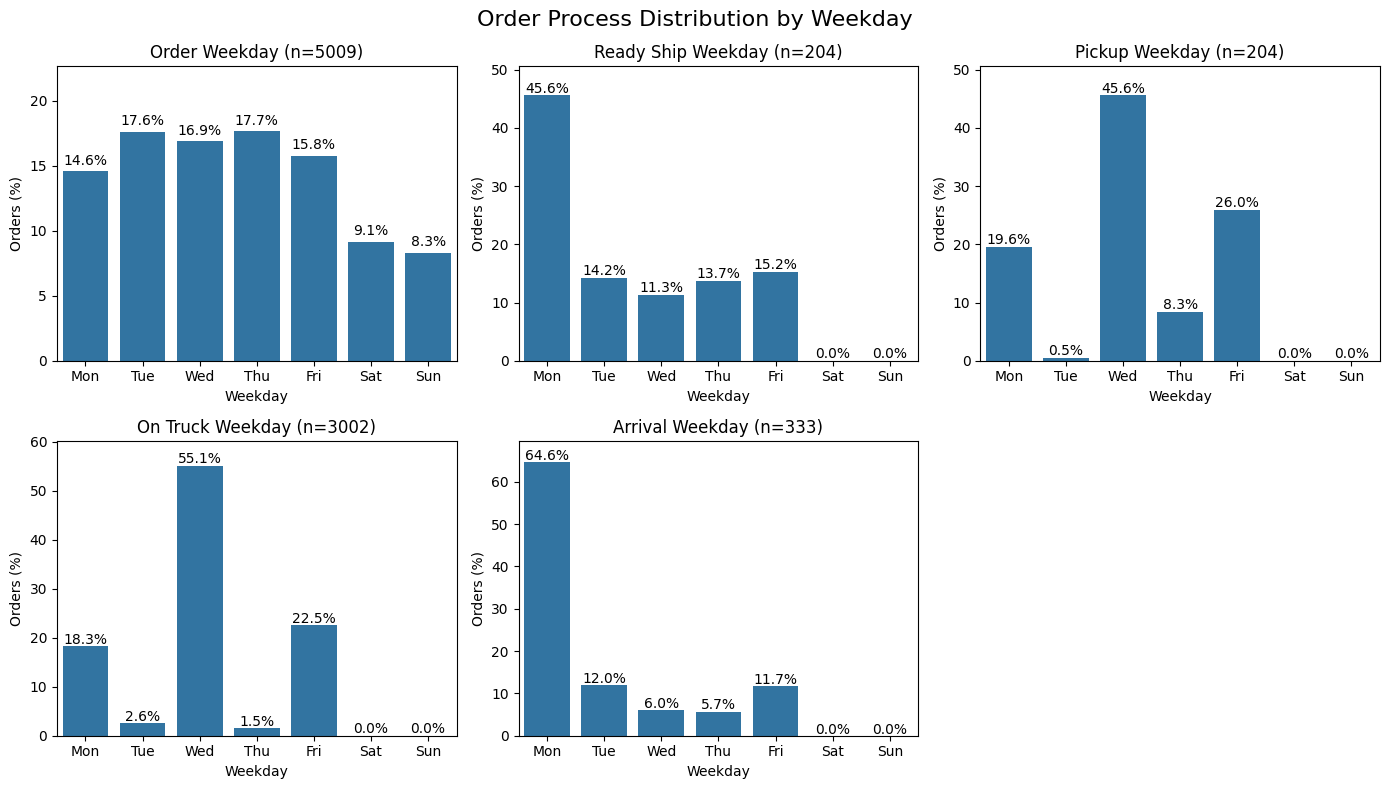

In [212]:
# trying with days names:
weekday_labels = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

# function to define daily distributions:
def weekday_distribution(series):
    counts = (
        series.dropna()
        .value_counts()
        .reindex(range(7), fill_value=0)   # ensures Mon–Sun exist
        .sort_index()
    )
    
    percent = counts / counts.sum() * 100
    percent.index = weekday_labels
    return percent


# the metrics i want:
cols = [
    "order_weekday",
    "ready_ship_weekday",
    "pickup_weekday",
    "on_truck_weekday",
    "arrival_weekday"
]


# the plot
fig, axes = plt.subplots(2, 3, figsize=(14,8))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    
    n = df_unique_all[col].dropna().shape[0]   # sample size
    
    counts = weekday_distribution(df_unique_all[col])
    
    sns.barplot(x=counts.index, y=counts.values, ax=ax)
    
    ax.set_title(f"{col.replace('_',' ').title()} (n={n})")
    ax.set_xlabel("Weekday")
    ax.set_ylabel("Orders (%)")
    
    ax.set_ylim(0, counts.max() + 5)

    # percentage labels
    for i, v in enumerate(counts.values):
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")

# remove empty subplot
fig.delaxes(axes[-1])

plt.suptitle("Order Process Distribution by Weekday", fontsize=16)
plt.tight_layout()
plt.show()

## Boxplots and statistics for the business days
In the previous Notebook I took a look on the days distributions and descriptive statistics but I didn't take into account the business-days logic. So, here I'm taking a look on the same data (almost the same data) but with the business-days logic.

### By the shipment method
There are two columns in the dataset referencing the shipment method.
1. Company categories:
Muesli company has three options of shipment:
* ```'Standard Class'``` = 1772 clients 
* ```'Second Class'```= 568 clients
* ```'First Class'``` = 662 clients

2. Logistic company categories:
But the truck company has it's own logic:
* ```'Express'```= 662 clients
* ```'Standard Processing'```= 2340 clients

This means that truck company treats Second Class and First Class deliveries the same way and puts them into one category. It's not clear why and what does it mean for the clients.

See below:

In [213]:
df_unique_all.groupby(['ship_mode']).size()

ship_mode
First Class       1051
Second Class       964
Standard Class    2994
dtype: int64

In [215]:
df_unique_all.groupby(['truck_ship_mode']).size()

truck_ship_mode
Express                 662
Standard Processing    2340
dtype: int64

First, I want to see how
* processing time
* total delivety time
deviates, taking into account the shipment (Muesli shipment) options:

In [216]:
df_unique_all.columns

Index(['order_id', 'ship_mode', 'origin_channel', 'region', 'total_items',
       'truck_ship_mode', 'process_days_biz', 'truck_wait_days_biz',
       'war_wait_days_biz', 'transp_days_biz', 'total_delivery_days_biz',
       'order_weekday', 'ready_ship_weekday', 'pickup_weekday',
       'on_truck_weekday', 'arrival_weekday'],
      dtype='str')

In [217]:
statistics = ["process_days_biz",
    "truck_wait_days_biz",
    "war_wait_days_biz",
    "transp_days_biz",
    "total_delivery_days_biz"]

In [218]:
# by the Muesli shipment type:
df_unique_all.groupby("ship_mode")[statistics].describe().T

# # create an image from this table:
# fig, ax = plt.subplots(figsize=(12,6))
# ax.axis('tight')
# ax.axis('off')
# ax.set_title(metric.replace("_", " ").title())

# # Draw table
# ax.table(cellText=table_1.values,
#          colLabels=table_1.columns,
#          rowLabels=table_1.index,
#          loc='center')

# Save image
# plt.savefig("1_delivery_by_ship_mode_table.png", dpi=300, bbox_inches='tight')
# plt.show()

ship_mode                      First Class  Second Class  Standard Class
process_days_biz        count    53.000000     44.000000      107.000000
                        mean      1.396226      2.568182        3.532710
                        std       1.182234      0.974028        1.110140
                        min       0.000000      0.000000        0.000000
                        25%       0.000000      2.000000        3.000000
                        50%       2.000000      3.000000        4.000000
                        75%       2.000000      3.000000        4.000000
                        max       3.000000      5.000000        5.000000
truck_wait_days_biz     count    53.000000     44.000000      107.000000
                        mean      0.396226      1.659091        1.710280
                        std       0.531313      0.568277        0.629605
                        min       0.000000      1.000000        1.000000
                        25%       0.000000      1.000000        1.000000
                        50%       0.000000      2.000000        2.000000
                        75%       1.000000      2.000000        2.000000
                        max       2.000000      3.000000        3.000000
war_wait_days_biz       count    53.000000     44.000000      107.000000
                        mean      0.396226      1.659091        1.710280
                        std       0.531313      0.568277        0.629605
                        min       0.000000      1.000000        1.000000
                        25%       0.000000      1.000000        1.000000
                        50%       0.000000      2.000000        2.000000
                        75%       1.000000      2.000000        2.000000
                        max       2.000000      3.000000        3.000000
transp_days_biz         count    75.000000     58.000000      200.000000
                        mean      2.853333      2.862069        2.965000
                        std       1.204646      1.033615        0.822898
                        min       1.000000      1.000000        1.000000
                        25%       2.000000      2.000000        3.000000
                        50%       3.000000      3.000000        3.000000
                        75%       3.500000      3.000000        3.000000
                        max       5.000000      5.000000        5.000000
total_delivery_days_biz count    75.000000     58.000000      200.000000
                        mean      4.800000      7.344828        8.390000
                        std       1.515684      1.628170        1.366469
                        min       1.000000      5.000000        4.000000
                        25%       4.000000      6.000000        7.000000
                        50%       5.000000      7.000000        9.000000
                        75%       6.000000      9.000000        9.000000
                        max       9.000000     10.000000       12.000000

Now I want to see how the truck delivery class (Express or Standard Processing) affects the waiting time, transport time and total delivery time:

* WOW: the transportation median time is NO different for express and standard processing; truck company treats the transportation of both categories almost identically;

* WOW: total delivery time still differs significantly, even though it's not related directly to the truck company behavior; probably, it happens because "Standard Processing" by trucks overlaps with "Second Class" and "Standard Delivery" by Muesli;

* warehouse waiting days differ a lot for two categories;

* truck waiting days as well (the two represent -almost- the same measurement, just taken from two different sources: interns and truck company);

* processing time (in the warehouse) also differs significantly but again, it's related to the categories overlap



In [219]:
df_unique_all.groupby("truck_ship_mode")[statistics].describe().T

truck_ship_mode                  Express  Standard Processing
process_days_biz        count  53.000000           151.000000
                        mean    1.396226             3.251656
                        std     1.182234             1.155962
                        min     0.000000             0.000000
                        25%     0.000000             2.500000
                        50%     2.000000             3.000000
                        75%     2.000000             4.000000
                        max     3.000000             5.000000
truck_wait_days_biz     count  53.000000           151.000000
                        mean    0.396226             1.695364
                        std     0.531313             0.610938
                        min     0.000000             1.000000
                        25%     0.000000             1.000000
                        50%     0.000000             2.000000
                        75%     1.000000             2.000000
                        max     2.000000             3.000000
war_wait_days_biz       count  53.000000           151.000000
                        mean    0.396226             1.695364
                        std     0.531313             0.610938
                        min     0.000000             1.000000
                        25%     0.000000             1.000000
                        50%     0.000000             2.000000
                        75%     1.000000             2.000000
                        max     2.000000             3.000000
transp_days_biz         count  75.000000           258.000000
                        mean    2.853333             2.941860
                        std     1.204646             0.873581
                        min     1.000000             1.000000
                        25%     2.000000             3.000000
                        50%     3.000000             3.000000
                        75%     3.500000             3.000000
                        max     5.000000             5.000000
total_delivery_days_biz count  75.000000           258.000000
                        mean    4.800000             8.155039
                        std     1.515684             1.491609
                        min     1.000000             4.000000
                        25%     4.000000             7.000000
                        50%     5.000000             8.000000
                        75%     6.000000             9.000000
                        max     9.000000            12.000000

In [220]:
df_unique_all.columns

Index(['order_id', 'ship_mode', 'origin_channel', 'region', 'total_items',
       'truck_ship_mode', 'process_days_biz', 'truck_wait_days_biz',
       'war_wait_days_biz', 'transp_days_biz', 'total_delivery_days_biz',
       'order_weekday', 'ready_ship_weekday', 'pickup_weekday',
       'on_truck_weekday', 'arrival_weekday'],
      dtype='str')

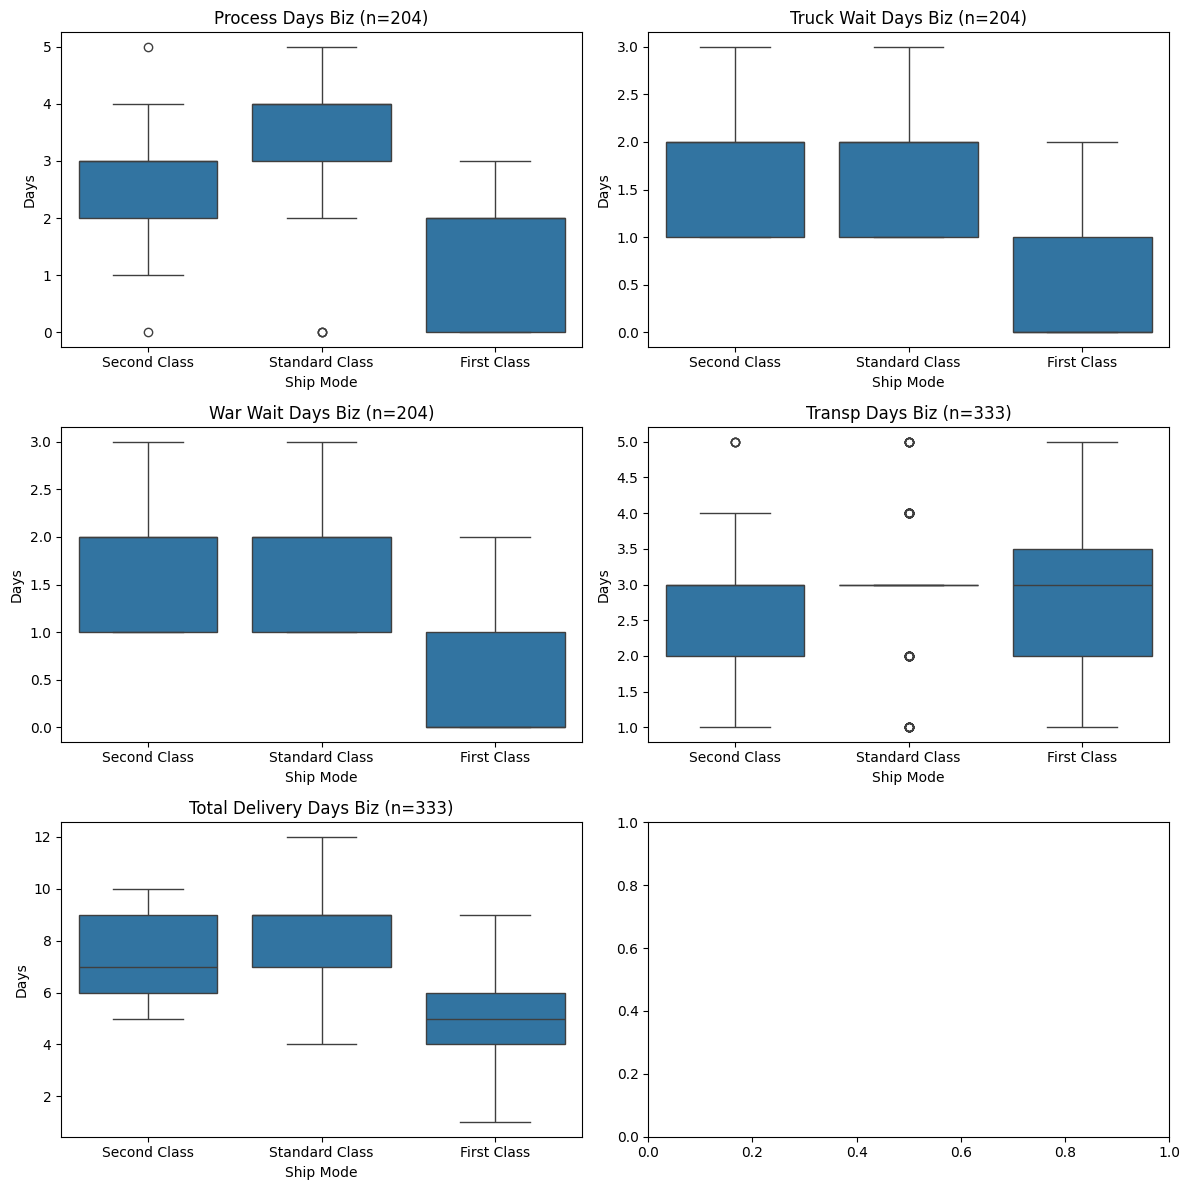

In [222]:
# if we want boxplots of the shipment modes (Muesli)

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, metric in zip(axes.flatten(), statistics):

    data = df_unique_all.dropna(subset=[metric])
    n = len(data)

    sns.boxplot(data=df_unique_all, x="ship_mode", y=metric, ax=ax)
    ax.set_title(f"{metric.replace('_', ' ').title()} (n={n})")
    ax.set_xlabel("Ship Mode")
    ax.set_ylabel("Days")

plt.tight_layout()
plt.show()

# plt.savefig("1_delivery_by_ship_mode.png", dpi=300, bbox_inches='tight')



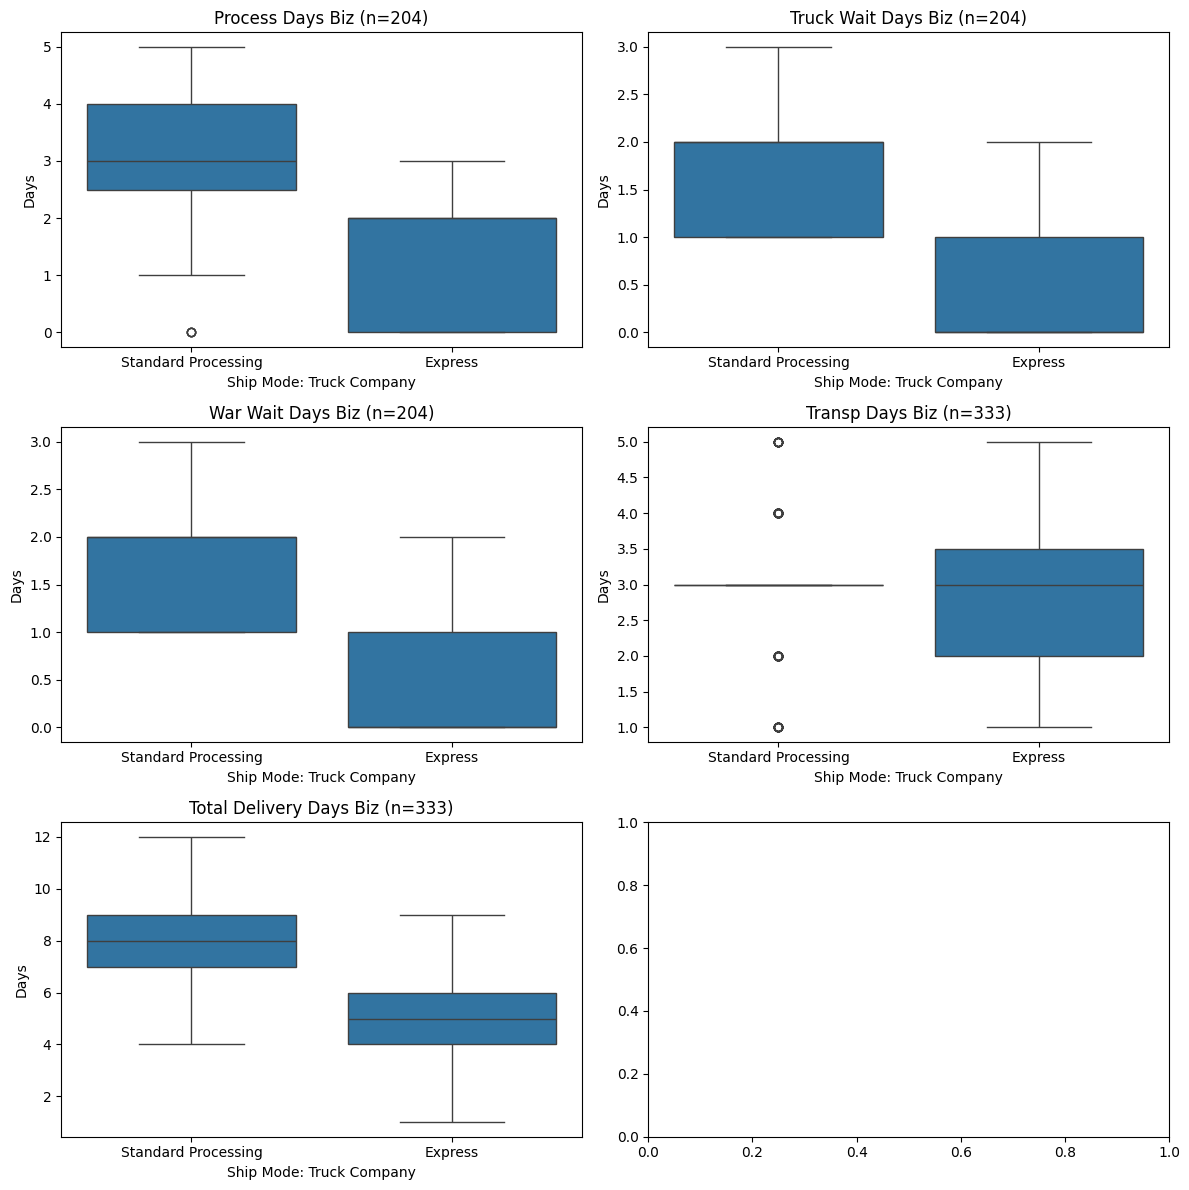

In [223]:
# if we want boxplots of the shipment modes (TRUCK COMPANY)

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, metric in zip(axes.flatten(), statistics):

    data = df_unique_all.dropna(subset=[metric])
    n= len(data)

    sns.boxplot(data=df_unique_all, x="truck_ship_mode", y=metric, ax=ax)
    ax.set_title(f"{metric.replace('_', ' ').title()} (n={n})")
    ax.set_xlabel("Ship Mode: Truck Company")
    ax.set_ylabel("Days")

plt.tight_layout()
plt.show()

# plt.savefig("1_delivery_by_ship_mode.png", dpi=300, bbox_inches='tight')



## Region -- does it affect the business days and delivery length?

In [224]:
df_unique_all.columns

Index(['order_id', 'ship_mode', 'origin_channel', 'region', 'total_items',
       'truck_ship_mode', 'process_days_biz', 'truck_wait_days_biz',
       'war_wait_days_biz', 'transp_days_biz', 'total_delivery_days_biz',
       'order_weekday', 'ready_ship_weekday', 'pickup_weekday',
       'on_truck_weekday', 'arrival_weekday'],
      dtype='str')

In [225]:
df_unique_all.groupby("region")[statistics].describe().T

region                           Central       East      South        West
process_days_biz        count  51.000000  52.000000  41.000000   60.000000
                        mean    2.823529   2.846154   2.975610    2.516667
                        std     1.410048   1.377474   1.214245    1.578367
                        min     0.000000   0.000000   0.000000    0.000000
                        25%     2.000000   2.000000   2.000000    2.000000
                        50%     3.000000   3.000000   3.000000    2.500000
                        75%     4.000000   4.000000   4.000000    4.000000
                        max     5.000000   5.000000   5.000000    5.000000
truck_wait_days_biz     count  51.000000  52.000000  41.000000   60.000000
                        mean    1.176471   1.269231   1.609756    1.416667
                        std     0.841567   0.744006   0.833008    0.829369
                        min     0.000000   0.000000   0.000000    0.000000
                        25%     0.500000   1.000000   1.000000    1.000000
                        50%     1.000000   1.000000   2.000000    1.000000
                        75%     2.000000   2.000000   2.000000    2.000000
                        max     3.000000   3.000000   3.000000    3.000000
war_wait_days_biz       count  51.000000  52.000000  41.000000   60.000000
                        mean    1.176471   1.269231   1.609756    1.416667
                        std     0.841567   0.744006   0.833008    0.829369
                        min     0.000000   0.000000   0.000000    0.000000
                        25%     0.500000   1.000000   1.000000    1.000000
                        50%     1.000000   1.000000   2.000000    1.000000
                        75%     2.000000   2.000000   2.000000    2.000000
                        max     3.000000   3.000000   3.000000    3.000000
transp_days_biz         count  77.000000  92.000000  49.000000  115.000000
                        mean    2.831169   2.902174   2.897959    3.008696
                        std     0.992108   0.984046   0.984143    0.903168
                        min     1.000000   1.000000   1.000000    1.000000
                        25%     2.000000   3.000000   3.000000    3.000000
                        50%     3.000000   3.000000   3.000000    3.000000
                        75%     3.000000   3.000000   3.000000    3.000000
                        max     5.000000   5.000000   5.000000    5.000000
total_delivery_days_biz count  77.000000  92.000000  49.000000  115.000000
                        mean    6.896104   7.336957   7.632653    7.686957
                        std     2.149568   2.087520   1.787618    2.014706
                        min     1.000000   2.000000   4.000000    3.000000
                        25%     6.000000   6.000000   6.000000    7.000000
                        50%     7.000000   8.000000   8.000000    8.000000
                        75%     9.000000   9.000000   9.000000    9.000000
                        max    11.000000  12.000000  10.000000   11.000000

## Amount of items vs, Delivery Time (business days)

In [148]:
# what are the amounts of items in the sample and how frequent they are:
df_unique_all.groupby('total_items').size()

total_items
1     152
2     370
3     377
4     265
5     313
6     190
7     221
8     178
9     156
10    137
11    101
12     79
13     59
14     67
15     56
16     41
17     34
18     27
19     27
20     16
21     21
22     21
23     17
24      9
25     11
26     10
27      4
28      4
29      5
30      5
31      4
32      5
33      4
34      2
35      1
36      1
37      1
38      1
39      1
40      1
41      2
42      1
43      2
46      2
52      1
dtype: int64

In [153]:
# what is the distribution of items' amount in the sample:
df_unique_all.groupby('total_items')['total_items'].describe().T

# >>> 'normal' bins (aka 10, 10-20, ...) won't work

total_items,1,2,3,4,5,6,7,8,9,10,...,36,37,38,39,40,41,42,43,46,52
count,152.0,370.0,377.0,265.0,313.0,190.0,221.0,178.0,156.0,137.0,...,1.0,1.0,1.0,1.0,1.0,2.0,1.0,2.0,2.0,1.0
mean,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,36.0,37.0,38.0,39.0,40.0,41.0,42.0,43.0,46.0,52.0
std,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,0.0,NaN
min,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,36.0,37.0,38.0,39.0,40.0,41.0,42.0,43.0,46.0,52.0
25%,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,36.0,37.0,38.0,39.0,40.0,41.0,42.0,43.0,46.0,52.0
50%,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,36.0,37.0,38.0,39.0,40.0,41.0,42.0,43.0,46.0,52.0
75%,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,36.0,37.0,38.0,39.0,40.0,41.0,42.0,43.0,46.0,52.0
max,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,36.0,37.0,38.0,39.0,40.0,41.0,42.0,43.0,46.0,52.0


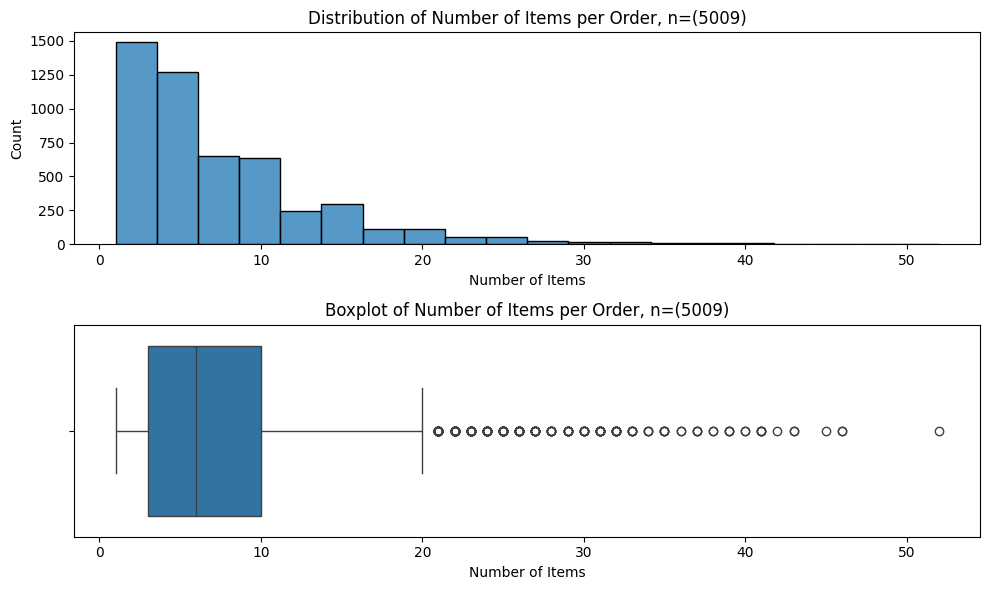

In [228]:
# some viz:
fig, axes = plt.subplots(2, 1, figsize=(10,6))

# histogram
n = len(df_unique_all['total_items'])
sns.histplot(df_unique_all["total_items"], bins=20, ax=axes[0])
axes[0].set_title(f"Distribution of Number of Items per Order, n=({n})")
axes[0].set_xlabel("Number of Items")
axes[0].set_ylabel("Count")

# boxplot
sns.boxplot(x=df_unique_all["total_items"], ax=axes[1])
axes[1].set_title(f"Boxplot of Number of Items per Order, n=({n})")
axes[1].set_xlabel("Number of Items")

plt.tight_layout()
plt.show()

In [229]:
# making bins:
bins = [0, 3, 10, 20, 100]
labels = ["1–3", "4–10", "11–20", "20+"]

df_unique_all["items_group"] = pd.cut(
    df_unique_all["total_items"],
    bins=bins,
    labels=labels
)

# Create a new column with the binned groups
df_unique_add["items_group"] = pd.cut(df_unique_all["total_items"],
                                    bins=bins,
                                    labels=labels,
                                    right=False)  # right=False means intervals like [0,10)

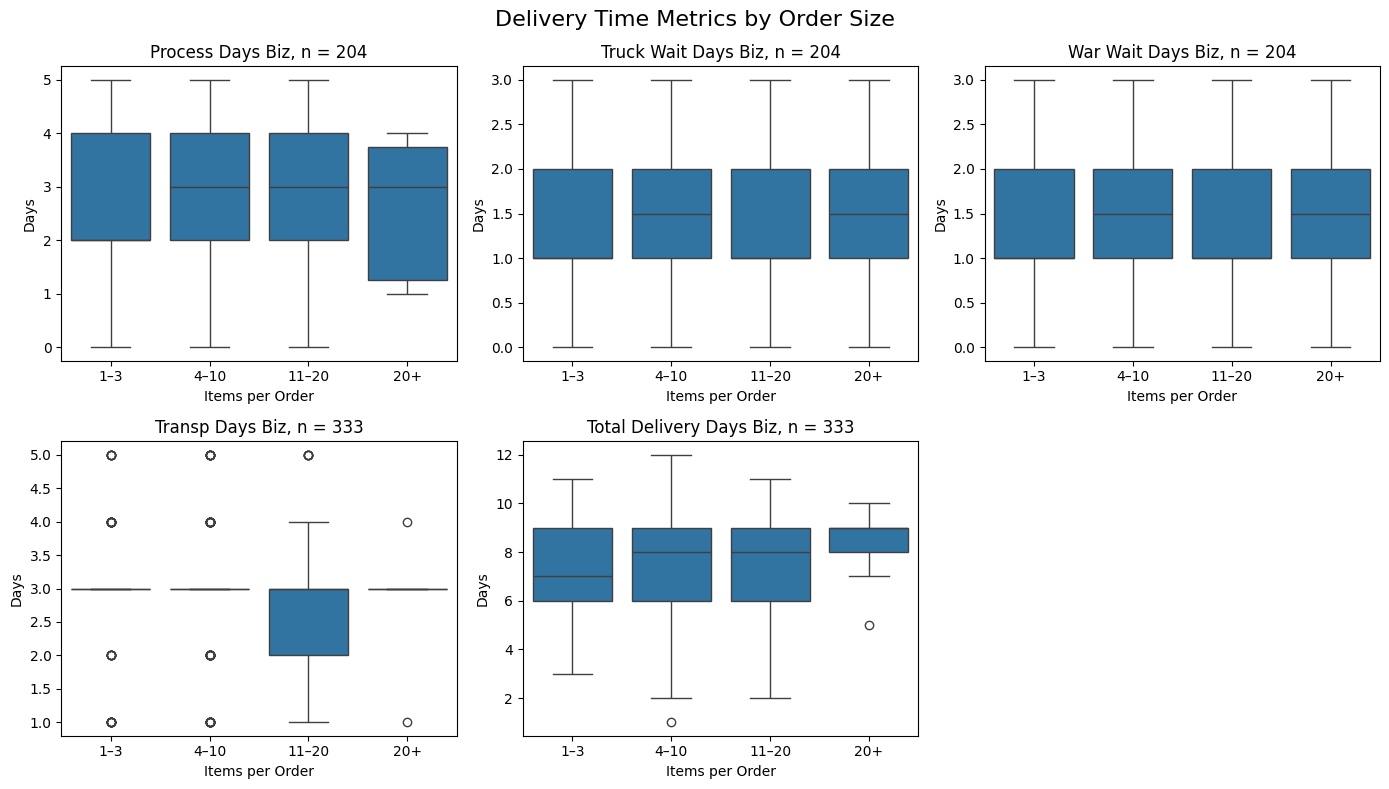

In [232]:
fig, axes = plt.subplots(2, 3, figsize=(14,8))
axes = axes.flatten()


for ax, metric in zip(axes, statistics):
    data = df_unique_all.dropna(subset=[metric])
    n = len(data)

    sns.boxplot(data=df_unique_all, x="items_group", y=metric, ax=ax)
    
    ax.set_title(f"{metric.replace('_', ' ').title()}, n = {n}")
    ax.set_xlabel("Items per Order")
    ax.set_ylabel("Days")

# remove the empty subplot
fig.delaxes(axes[-1])

plt.suptitle("Delivery Time Metrics by Order Size", fontsize=16)
plt.tight_layout()
plt.show()

# >>> almost no variation